Imports and paths

In [12]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [13]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
raw_data_dir = ROOT / "data" / "raw"
reports_figures = ROOT / "reports" / "figures"

Loading the data

In [14]:
competitions = pd.read_csv(raw_data_dir / "competitions.csv.gz")
clubs = pd.read_csv(raw_data_dir / "clubs.csv.gz")
valuations = pd.read_csv(raw_data_dir / "player_valuations.csv.gz")
players = pd.read_csv(raw_data_dir / "players.csv.gz")
appearances = pd.read_csv(raw_data_dir / "appearances.csv.gz")

The Premier League clubs of the 2025-26 season

In [15]:
pl_clubs = clubs[(clubs["domestic_competition_id"] == "GB1") & (clubs["last_season"] == 2025)]
display(pl_clubs)
print(f"Number of Premier League clubs: {len(pl_clubs['name'])}")

,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,filename,url
50,11,fc-arsenal,Arsenal FC,GB1,NaN,29,26.2,19,65.5,21,Emirates Stadium,60704,€-20.00m,Mikel Arteta,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-arsenal/sta...
67,1132,fc-burnley,Burnley FC,GB1,NaN,30,25.9,24,80.0,12,Turf Moor,21994,€-6.50m,Scott Parker,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-burnley/sta...
72,1148,fc-brentford,Brentford FC,GB1,NaN,34,25.0,25,73.5,16,Gtech Community Stadium,17250,€-28.50m,Keith Andrews,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-brentford/s...
97,1237,brighton-amp-hove-albion,Brighton & Hove Albion,GB1,NaN,37,25.0,29,78.4,19,AMEX Stadium,31876,€-8.70m,Fabian Hürzeler,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/brighton-amp-h...
154,148,tottenham-hotspur,Tottenham Hotspur,GB1,NaN,37,25.5,28,75.7,24,Tottenham Hotspur Stadium,62850,€-251.20m,Thomas Frank,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/tottenham-hots...
333,281,manchester-city,Manchester City,GB1,NaN,32,25.2,20,62.5,22,Etihad Stadium,61000,€-152.03m,Pep Guardiola,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/manchester-cit...
343,289,afc-sunderland,Sunderland AFC,GB1,NaN,31,25.7,25,80.6,16,Stadium of Light,48707,+€22.00m,Régis Le Bris,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/afc-sunderland...
345,29,fc-everton,Everton FC,GB1,NaN,23,25.8,11,47.8,9,Hill Dickinson Stadium,52769,€-65.30m,David Moyes,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-everton/sta...
368,31,fc-liverpool,Liverpool FC,GB1,NaN,29,25.4,22,75.9,18,Anfield,61276,€-103.60m,Arne Slot,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-liverpool/s...
447,379,west-ham-united,West Ham United,GB1,NaN,27,25.8,17,63.0,11,London Stadium,62500,+€97.85m,Graham Potter,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/west-ham-unite...


Number of Premier League clubs: 20


Let’s go and look at Arsenal’s squad, the PL champions of the 2025-26 season.

In [16]:
TEAM_FILTER = "Arsenal FC"

arsenal_players = players[
    players["current_club_id"].isin(pl_clubs[pl_clubs["name"] == TEAM_FILTER]["club_id"])
    & (players["last_season"] == 2025)
]

arsenal_players[
    ["first_name", "last_name", "position", "market_value_in_eur"]
].sort_values("position", key=lambda x: x.map({"Goalkeeper": 0, "Defender": 1, "Midfield": 2, "Attack": 3}))

,first_name,last_name,position,market_value_in_eur
45898,Jack,Porter,Goalkeeper,300000.0
12889,Kepa,Arrizabalaga,Goalkeeper,5000000.0
16803,David,Raya,Goalkeeper,30000000.0
45102,Khari,Ranson,Goalkeeper,NaN
41335,Alexéi,Rojas,Goalkeeper,250000.0
38762,Tommy,Setford,Goalkeeper,500000.0
27847,Riccardo,Calafiori,Defender,55000000.0
43071,Jaden,Dixon,Defender,NaN
41927,Josh,Nichols,Defender,NaN
39767,Myles,Lewis-Skelly,Defender,45000000.0


Market value of each Arsenal player

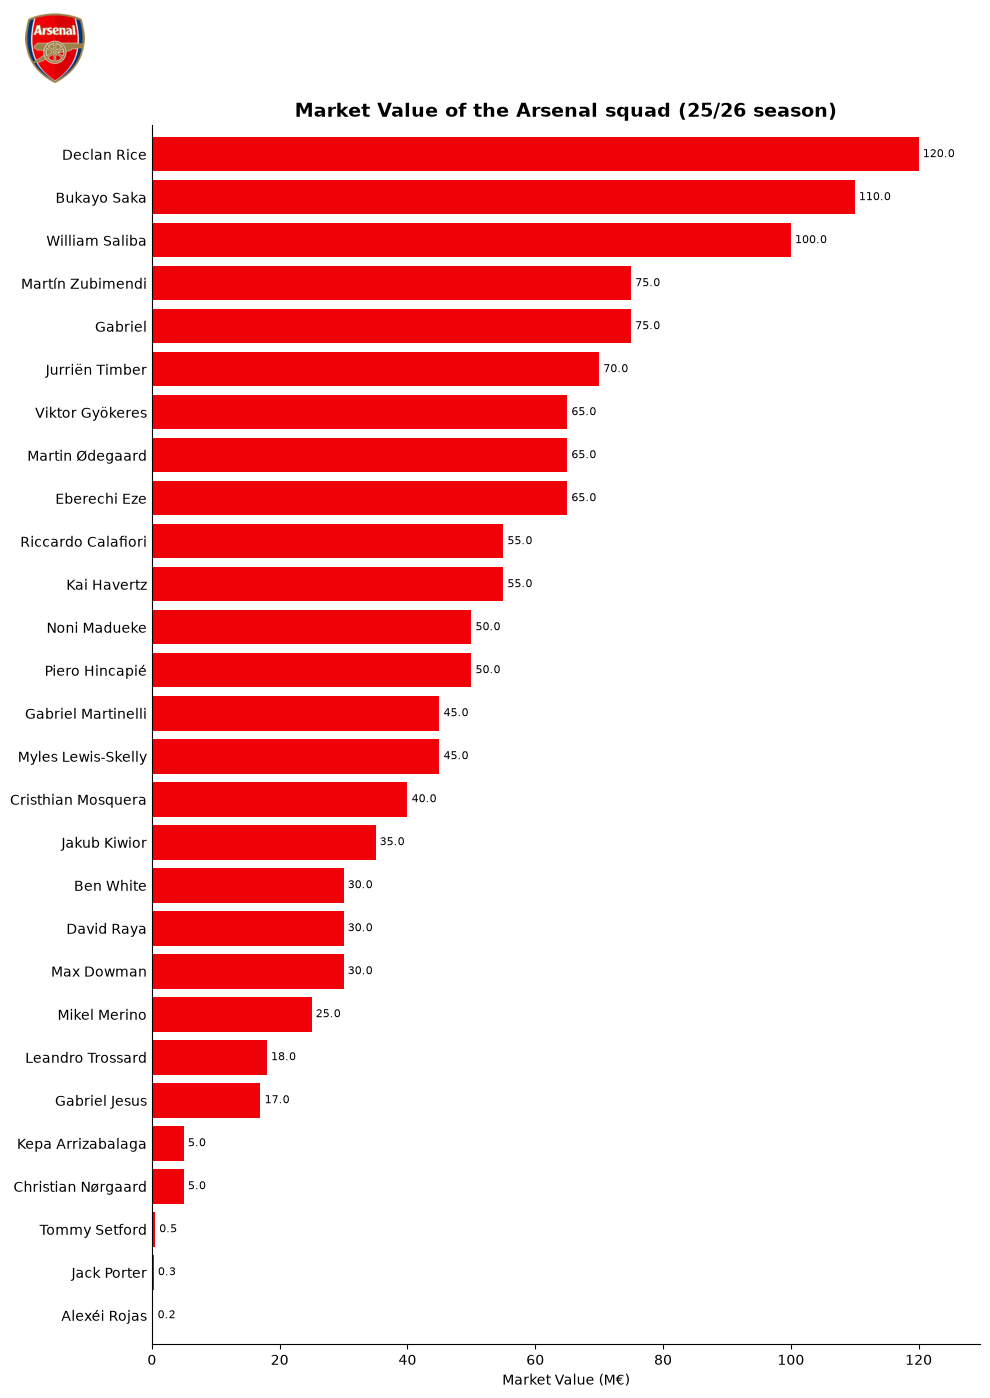

In [23]:
ARSENAL_ID = 11
LAST_SEASON = 2025

a = players[
    (players["current_club_id"] == ARSENAL_ID)
    & (players["last_season"] == LAST_SEASON)
].dropna(subset=["market_value_in_eur"])

a = a.sort_values("market_value_in_eur", ascending=True)

fig, ax = plt.subplots(figsize=(10, 14))
values = a["market_value_in_eur"] / 1e6
bars = ax.barh(a["name"], values, color="#EF0107")
ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=3, fontsize=8)
ax.set_xlabel("Market Value (M€)")
ax.set_title("Market Value of the Arsenal squad (25/26 season)", fontsize=14, fontweight="bold")
ax.margins(x=0.08, y=0.01)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout(rect=[0, 0, 1, 0.94])

logo_ax = fig.add_axes([0.02, 0.94, 0.08, 0.055])
logo_ax.imshow(plt.imread(ROOT / "assets" / "arsenal_logo.png"))
logo_ax.axis("off")

plt.savefig(reports_figures / "arsenal_squad_market_value.png", dpi=150)
plt.show()

We can also look at the squad composition by position for each team

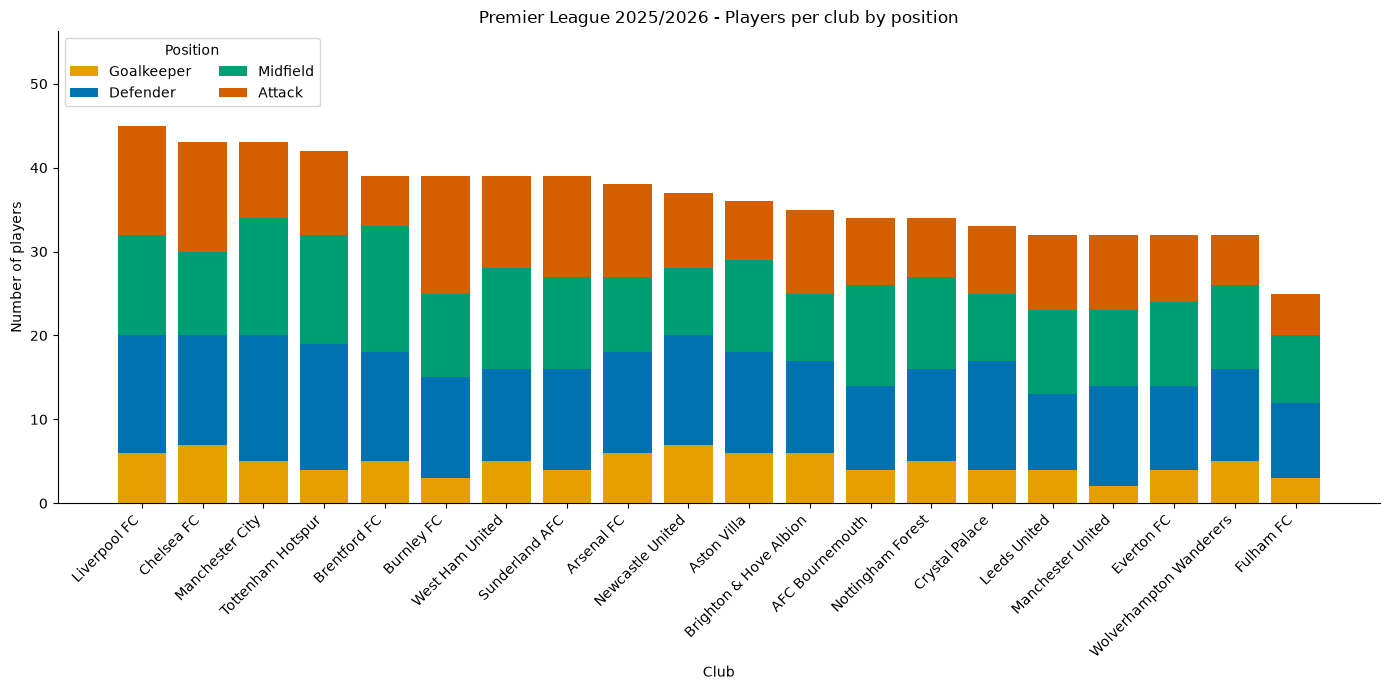

In [18]:
positions = ["Goalkeeper", "Defender", "Midfield", "Attack"]
colors = {"Goalkeeper": "#E69F00", "Defender": "#0072B2", "Midfield": "#009E73", "Attack": "#D55E00"}

pl_players = players[
    players["current_club_id"].isin(pl_clubs["club_id"]) & (players["last_season"] == 2025)
].merge(pl_clubs[["club_id", "name"]].rename(columns={"name": "club"}), left_on="current_club_id", right_on="club_id")

counts = (
    pl_players.groupby(["club", "position"]).size().unstack(fill_value=0)
    .reindex(columns=positions, fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(14, 7))
bottom = pd.Series(0, index=counts.index)
for pos in positions:
    ax.bar(counts.index, counts[pos], bottom=bottom, color=colors[pos], label=pos)
    bottom += counts[pos]

ax.set_xlabel("Club")
ax.set_ylabel("Number of players")
ax.set_title("Premier League 2025/2026 - Players per club by position")
ax.set_ylim(0, bottom.max() * 1.25)
ax.legend(loc="upper left", title="Position", ncol=2)
plt.xticks(rotation=45, ha="right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "players_per_club_by_position.png", dpi=150)
plt.show()

The top 5 players by market value for each team

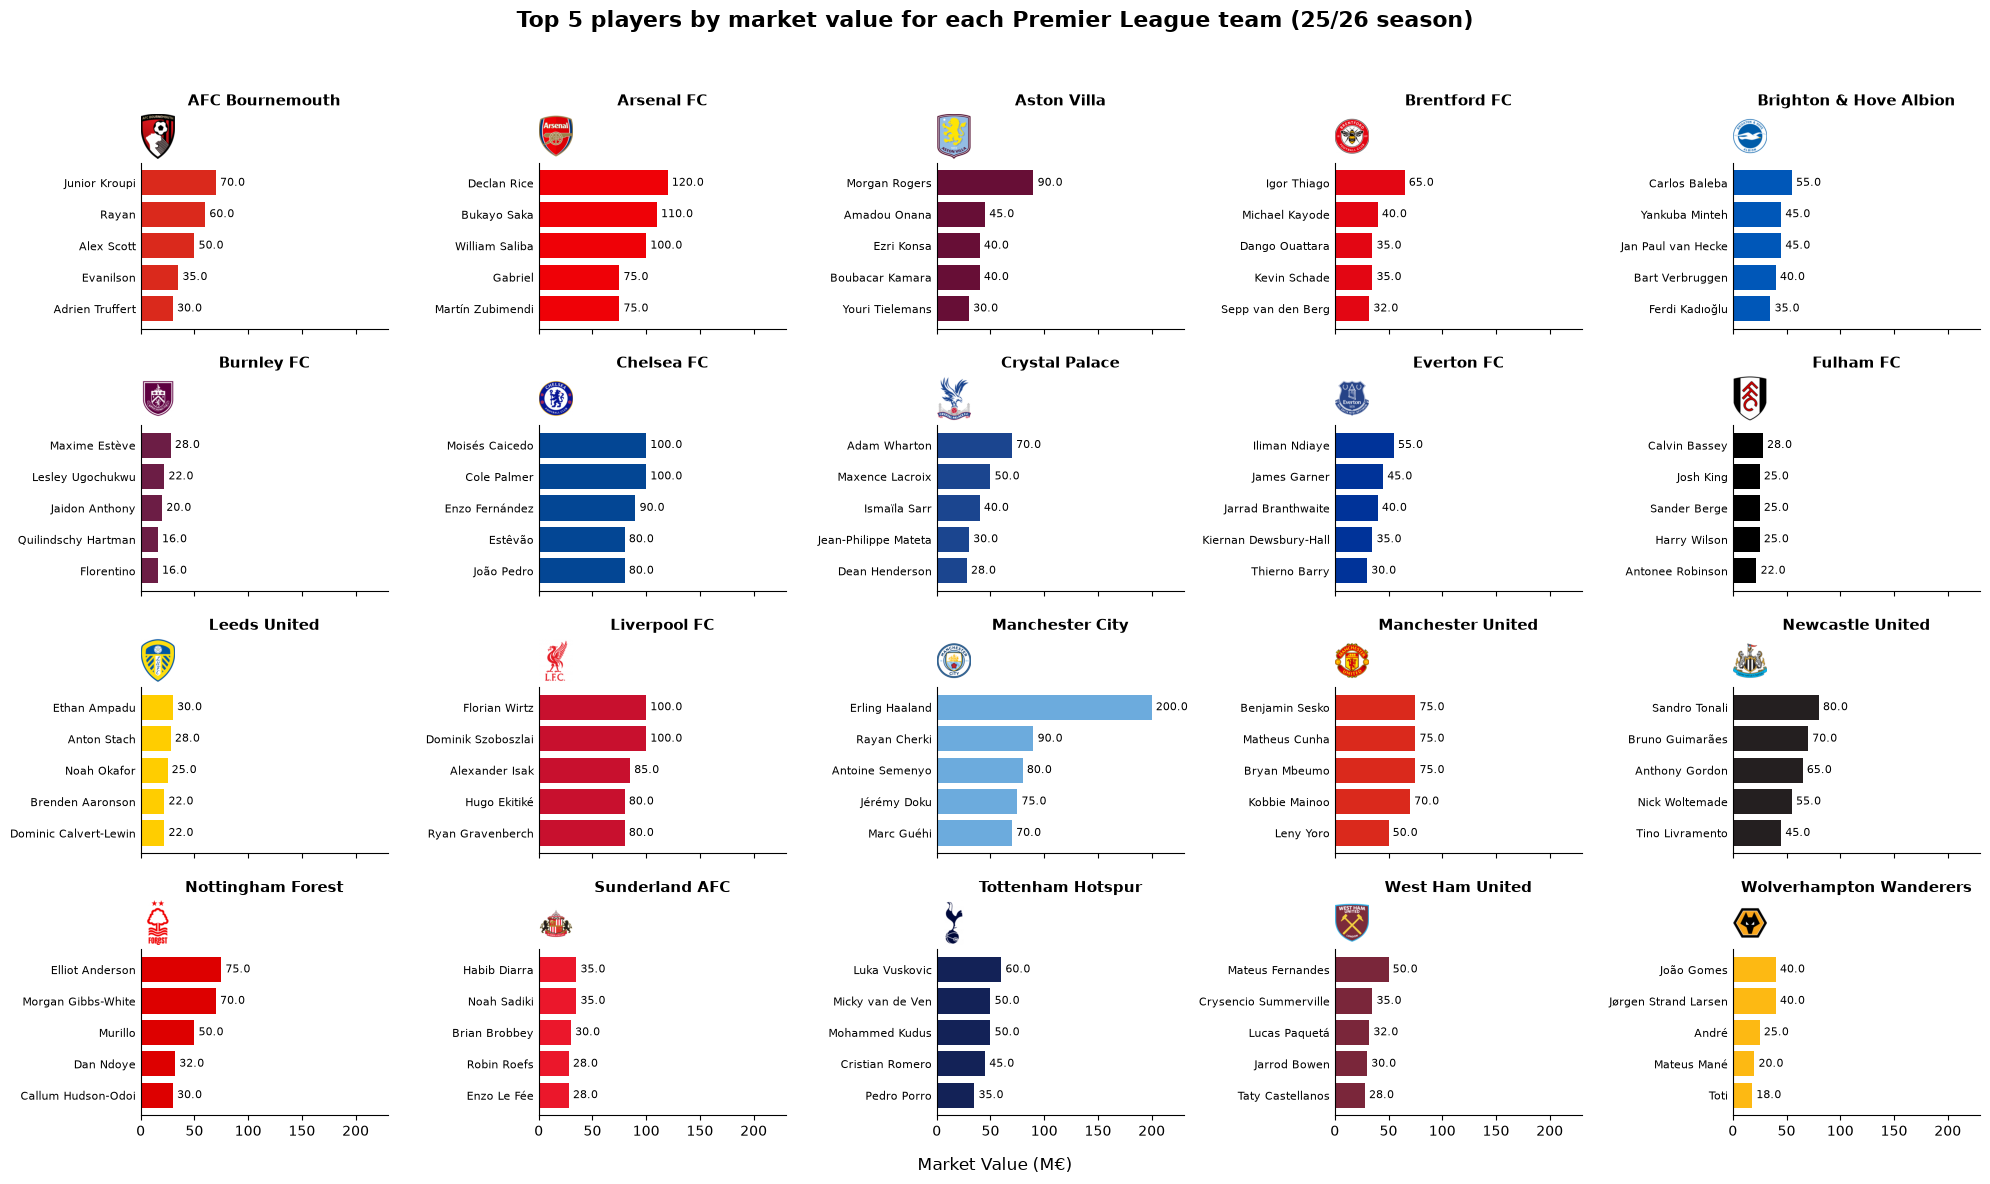

In [25]:
CLUB_COLORS = {
    11: "#EF0107",    # Arsenal
    1132: "#6C1D45",  # Burnley
    1148: "#E30613",  # Brentford 
    1237: "#0057B8",  # Brighton
    148: "#132257",   # Tottenham
    281: "#6CABDD",   # Manchester City
    289: "#EB172B",   # Sunderland 
    29: "#003399",    # Everton
    31: "#C8102E",    # Liverpool
    379: "#7A263A",   # West Ham
    399: "#FFCD00",   # Leeds
    405: "#670E36",   # Aston Villa
    543: "#FDB913",   # Wolves
    631: "#034694",   # Chelsea
    703: "#DD0000",   # Nottingham Forest
    762: "#241F20",   # Newcastle
    873: "#1B458F",   # Crystal Palace
    931: "#000000",   # Fulham
    985: "#DA291C",   # Manchester United
    989: "#DA291C",   # Bournemouth
}

pl_players = players[
    (players["current_club_id"].isin(pl_clubs["club_id"]))
    & (players["last_season"] == 2025)
].dropna(subset=["market_value_in_eur"])

top5 = pl_players.groupby("current_club_id").apply(
    lambda x: x.nlargest(5, "market_value_in_eur"), include_groups=False
).reset_index(level=0)

fig, axes = plt.subplots(4, 5, figsize=(20,12), sharex=True)
for ax, (_, club) in zip(axes.flat, pl_clubs.sort_values("name").iterrows()) :
    logo = plt.imread(ROOT / "assets" / "clubs_logo" / f"{club["club_id"]}.png")
    t = top5[top5["current_club_id"] == club["club_id"]].sort_values("market_value_in_eur")
    values = t["market_value_in_eur"] / 1e6
    bars = ax.barh(t["name"], values, color = CLUB_COLORS[club["club_id"]])
    ax.bar_label(bars, labels=[f"{v}" for v in values], padding = 3, fontsize = 8)
    ax.set_title(club["name"], fontsize=11, fontweight="bold")
    ax.margins(x=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=8)

    logo_ax = ax.inset_axes([0, 1.02, 0.14, 0.28])
    logo_ax.imshow(logo)
    logo_ax.axis("off")

fig.suptitle("Top 5 players by market value for each Premier League team (25/26 season)", fontsize=16, fontweight="bold")
fig.supxlabel("Market Value (M€)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(reports_figures / "top5_players_per_team.png", dpi=150)
plt.show()